# 01 · The testbed and its batches

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p05_when_to_stop/notebooks/01_the_testbed_and_its_batches.ipynb)

**Project 5 — When to stop.** Every cycle in a desalination plant gets dearer the longer it runs, and
ending it has a fixed price. The project asks one question at four time scales: *when should the
cycle end?* This notebook opens the first and fastest of them: a **closed-circuit RO batch**.

A closed-circuit RO unit keeps its brine in a loop. A feed pump tops the loop up exactly as fast as
permeate leaves, so the loop concentrates; when the reject conductivity reaches a chosen value, the
batch ends and the brine is pushed out with fresh feed. Run it longer and each cubic metre costs more
energy (the osmotic pressure climbs); stop it sooner and you drain more brine per cubic metre made.
Somewhere between is the cheapest end.

**Data:** a public closed-circuit reverse-osmosis (CCRO) testbed record, "Foundational Control Methods for Water Treatment Systems — Online Actuator and Sensor Data", [doi:10.7481/1963162](https://doi.org/10.7481/1963162), CC BY 4.0: 881 batch files from June to October 2021. The notebooks read the tables committed in `results/` and a 0.8 MB excerpt of five batch files; the 351 MB of zips are needed only where a cell says so.

Script version: `step1_ccro_audit.py` · record: `VALIDATION.md`, section 1.

In [1]:
# Setup. In Google Colab this clones the repository and installs the package (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz,data]"
import os, subprocess, sys
from pathlib import Path
REF = "main"        # before the Project 5 pull request is merged, use "p05-when-to-stop"
if "google.colab" in sys.modules:
    if not Path("/content/chemai").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REF,
                        "https://github.com/EngMtaleb/chemai.git", "/content/chemai"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/content/chemai[viz,data]"], check=True)
    sys.path.insert(0, "/content/chemai")
    ROOT = Path("/content/chemai")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
P5 = ROOT / "projects" / "p05_when_to_stop"
RES = P5 / "results"
sys.path.insert(0, str(P5))          # the step scripts, for the helpers they define

import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
INK, MUTED, BLUE, ORANGE, GREEN, RED, TEAL = "#1f2933", "#7b8794", "#2f6fb2", "#d9822b", "#3f8f5a", "#c23b3b", "#0f7c8c"

def load(name):
    """A committed result file from projects/p05_when_to_stop/results/."""
    return json.loads((RES / name).read_text())

## 0. The record

Seven zip files. Their sizes and sha256 are written in `chemai/config.py`, and `check_files` refuses
any that differ. The zips are read as text only: one experiment folder ships a 216 MB Python pickle,
which is never opened — a pickle can run code.

To rebuild everything from the zips, set `FULL = True` (a 351 MB download from the record, then about
ten minutes to convert).

In [2]:
from chemai.config import CCROConfig
cfg = CCROConfig()
FULL = False
if FULL:
    from chemai.data.nawi_ccro import convert_all, download_files
    print(download_files(cfg)[["file", "sha256_ok"]])
    convert_all(cfg)          # then run step1_ccro_audit.py for the batch table

audit = load("step1_ccro_audit.json")
pd.DataFrame(audit["datasets"]).T[["files", "first", "last", "median_dt_s", "has_states"]]

,files,first,last,median_dt_s,has_states
dataset1,1,2021-06-03 13:33:33,2021-06-03 16:28:54,1.001,True
dataset2,35,0288-10-23 09:12:43,2021-06-02 08:58:04,0.252,False
dataset3,584,2021-06-13 18:27:40,2021-07-14 20:34:20,0.714,True
dataset4,39,2021-08-23 16:12:54,2021-08-26 07:32:17,0.436,True
dataset5,98,2021-09-16 15:46:34,2021-09-24 19:03:53,0.268,True
dataset6,159,2021-10-06 15:02:34,2021-10-21 09:32:31,0.254,True


Six datasets. Two are set aside: dataset 1 is one conventional run at a different (12 mS/cm) feed
whose phases carry other names, and dataset 2 has no phase labels at all (one of its files even starts
in the year 288). The other four are the project's material:

| Dataset | What ran | Used as |
|---|---|---|
| 3 | **extremum-seeking control** (ESC) choosing each batch's end | development |
| 4 | open-loop and set-point-step experiments | development |
| 5 | model-predictive control (MPC) moving the flows inside each batch | outside the rule's scope |
| 6 | **Bayesian optimisation** (BO) choosing each batch's end | **test, scored once** |

## 1. One batch, phase by phase

Each file holds one batch — and, at its start, the drain of the *previous* batch's brine. The
excerpt below is a test batch (BO Exp1 no. 11) and the start of the next file, where its brine
leaves.

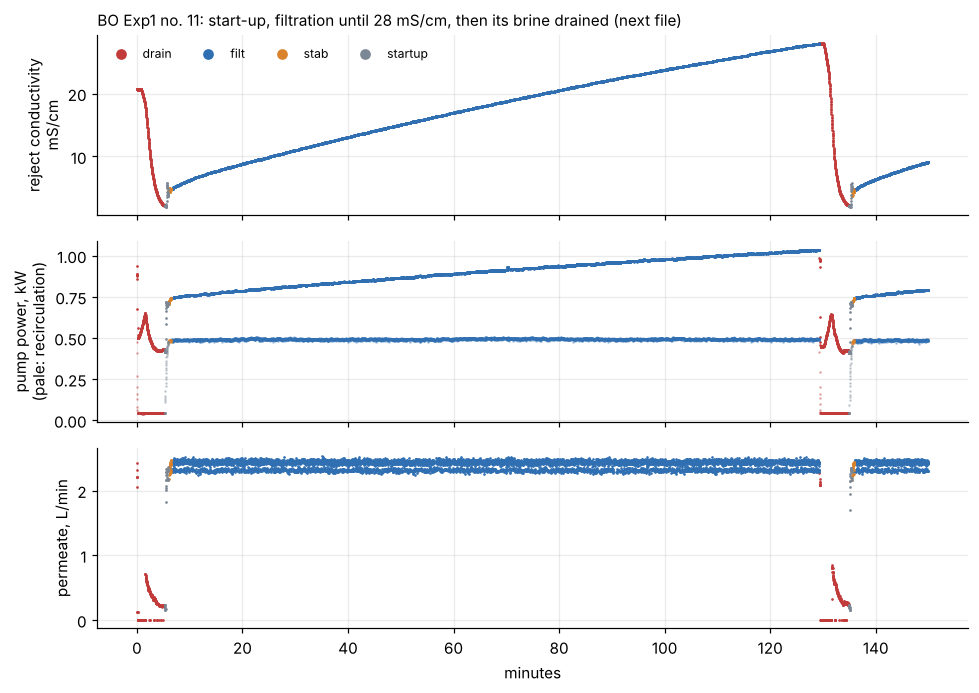

In [3]:
x = pd.read_parquet(RES / "excerpt_batches.parquet")
from chemai.features.ccro_batches import phase_of
x["phase"] = x.state.map(phase_of)
b11 = x[(x.dataset == "dataset6") & (x.seq.isin([11, 12]))].copy()
b11["minutes"] = (b11.ts - b11.ts.iloc[0]).dt.total_seconds() / 60
b11 = b11[b11.minutes < 150]
fig, axes = plt.subplots(3, 1, figsize=(9, 6.4), sharex=True)
col = {"drain": RED, "startup": MUTED, "stab": ORANGE, "filt": BLUE}
for ph, g in b11.groupby("phase"):
    axes[0].plot(g.minutes, g.reject_conductivity_ms_per_cm, ".", ms=1.5, color=col.get(ph, INK), label=ph)
    axes[1].plot(g.minutes, g.feed_pump_power_draw_kw, ".", ms=1.5, color=col.get(ph, INK))
    axes[1].plot(g.minutes, g.recirculation_pump_power_draw_kw, ".", ms=1.5, color=col.get(ph, INK), alpha=0.35)
    axes[2].plot(g.minutes, g.permeate_flow_l_per_min, ".", ms=1.5, color=col.get(ph, INK))
axes[0].set_ylabel("reject conductivity\nmS/cm"); axes[1].set_ylabel("pump power, kW\n(pale: recirculation)")
axes[2].set_ylabel("permeate, L/min"); axes[2].set_xlabel("minutes")
axes[0].legend(markerscale=8, frameon=False, ncol=4, fontsize=8)
axes[0].set_title("BO Exp1 no. 11: start-up, filtration until 28 mS/cm, then its brine drained (next file)",
                  loc="left", fontsize=10)
plt.tight_layout()

Three things to see. The conductivity climbs in a nearly straight line during filtration: salt
comes in with the feed and stays. The feed pump's power climbs with it — it has to push against a
rising osmotic pressure. And the **recirculation pump draws half to two-thirds as much power as the
feed pump** while making no permeate: on a one-element testbed both pumps are oversized, which is why
this testbed spends about 10 kWh per m³, ten times a full-scale plant. Keep that in mind: the *shape* of the curve is physics,
its *level* is this testbed's pumps.

## 2. From samples to a table of batches

`batch_table` integrates each phase — energy, permeate, the flow through the reject line — and gives
each batch the brine drained at the start of the next file, provided that file is numbered next and
starts within two minutes.

In [4]:
from chemai.features.ccro_batches import batch_table
t = batch_table(x[x.dataset == "dataset6"].assign(**{c: np.nan for c in ["permeate_conductivity_us_per_cm",
                                                                         "set_low_rej_cond_ms_per_cm"]}))
t[["seq", "filt_min", "c_start", "c_end", "V_l", "brine_l", "own_drain_kwh", "sec", "sbc"]].round(3)

,seq,filt_min,c_start,c_end,V_l,brine_l,own_drain_kwh,sec,sbc
0,11,122.801,4.886,27.930,297.111,15.662,0.05,9.855,0.053
1,12,71.566,4.809,19.961,173.706,NaN,NaN,NaN,NaN


Batch 11 made about 300 L of permeate at 10 kWh/m³ and left about 15 L of brine. Batch 12's brine is not
in the excerpt, so its cost cannot be closed — the table leaves it blank rather than guess.

The committed table holds all 881 files:

In [5]:
B = pd.read_parquet(RES / "ccro_batches.parquet")
B = B[B.filt_min > 0]
B.groupby(["dataset", "exp"]).agg(batches=("seq", "size"), filtration_min=("filt_min", "median"),
                                   end_mS_cm=("c_end", "median"), flux_LMH=("flux", "median"),
                                   recirc_L_min=("q_recirc", "median"), held_setpoints=("constant_setpoints", "mean"),
                                   kWh_m3=("sec", "median"), brine_per_permeate=("sbc", "median")).round(2)

batches  filtration_min  end_mS_cm  flux_LMH  recirc_L_min  held_setpoints  \
dataset  exp                                                                                                                          
dataset3 Exp1                                                204           10.84       7.18     20.17         49.98             1.0   
         Exp2                                                 58           23.17      10.49     20.19         49.98             1.0   
         Exp2_continued/Data                                  43           34.87      13.25     20.19         49.98             1.0   
         Exp3                                                279           32.98      15.42     20.18         44.77             1.0   
dataset4 Open Loop Experiments                                 9           86.58      24.94     17.78         48.70             1.0   
         Set Point Step Change Experiment/Step Change 1       15           83.96      24.98     17.14         49.63             0.0   
         Set Point Step Change Experiment/Step Change 2       14           79.00      24.98     17.38         49.69             0.0   
dataset5 Exp1/Data                                            29           52.40      24.92     24.73         45.29             0.0   
         Exp2/Data                                            24           52.10      24.98     24.72         45.31             0.0   
         Exp3A/Data                                           10           91.76      24.98      8.66         45.28             0.0   
         Exp3B/Data                                           11          173.11      24.98      8.36         45.26             0.0   
         Exp4/Data                                            24           48.54      16.96     24.74         45.27             0.0   
dataset6 Exp1                                                 41           44.63      14.43     20.20         44.93             1.0   
         Exp2                                                 90           62.48      21.38     20.21         44.90             1.0   
         Exp3A                                                18           67.37      22.19     20.21         44.94             1.0   
         Exp3B                                                10          105.81      26.55     20.21         44.98             1.0   

                                                         kWh_m3  brine_per_permeate  
dataset  exp                                                                         
dataset3 Exp1                                             12.30                0.48  
         Exp2                                             12.33                0.26  
         Exp2_continued/Data                              12.39                0.19  
         Exp3                                             11.74                0.20  
dataset4 Open Loop Experiments                            12.10                0.10  
         Set Point Step Change Experiment/Step Change 1   12.38                0.09  
         Set Point Step Change Experiment/Step Change 2   12.46                0.10  
dataset5 Exp1/Data                                         9.83                0.11  
         Exp2/Data                                         9.97                0.11  
         Exp3A/Data                                       12.79                0.09  
         Exp3B/Data                                       13.31                0.05  
         Exp4/Data                                         9.78                0.10  
dataset6 Exp1                                              9.80                0.12  
         Exp2                                             10.47                0.10  
         Exp3A                                            10.95                0.10  
         Exp3B                                             9.83                0.06

## 3. What a batch costs

The testbed's own optimisers minimised

$$J = \text{SEC} + b \cdot \text{SBC}$$

the energy per m³ of permeate plus *b* times the brine per m³ of permeate. *b* is a price: brine in
kWh per m³ of brine. With electricity at $0.10/kWh, b = 1 is brine at $0.10/m³ and b = 10 is brine at
$1/m³. Their code (in the ESC folder of the record) leaves start-up and stabilisation out of both
terms and gives each batch the previous batch's brine; this project counts everything and gives each
batch its own brine.

## 4. What the optimisers chose

Each optimiser picked the conductivity at which each batch would end.

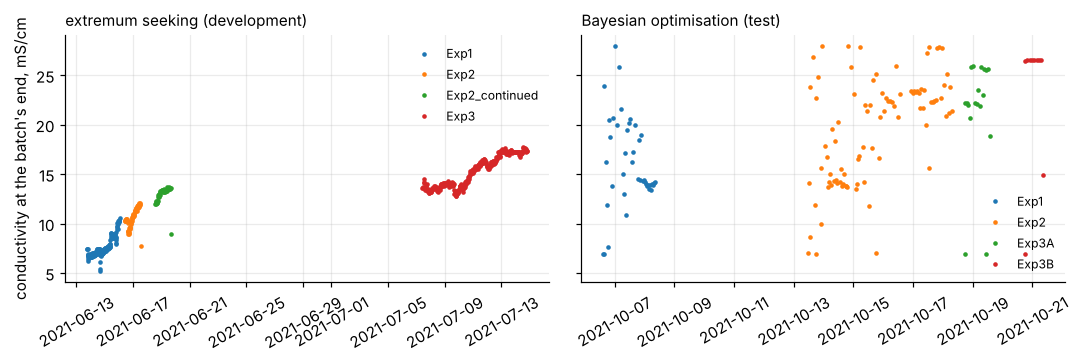

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, ds, title in ((axes[0], "dataset3", "extremum seeking (development)"),
                      (axes[1], "dataset6", "Bayesian optimisation (test)")):
    g = B[B.dataset == ds].sort_values("t_first")
    for exp, gg in g.groupby("exp"):
        ax.plot(gg.t_first, gg.c_end, ".", ms=4, label=exp.split("/")[0])
    ax.set_title(title, loc="left", fontsize=10); ax.tick_params(axis="x", rotation=30)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("conductivity at the batch's end, mS/cm")
plt.tight_layout()

The two optimisers wandered very differently. Extremum seeking moves a little each batch: in its
b = 1 experiment it spent two days drifting between 7 and 10 mS/cm. Bayesian optimisation jumps around
— 7, 24, 12, 28 mS/cm — to learn the shape of the cost before settling. Both search *across* batches.

**The next notebook** asks whether a batch can find its own best end, from its own live signal,
with no search at all.